In [60]:
import sys
!{sys.executable} -m pip install plumed

Looking in links: /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/x86-64-v3, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/generic, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/generic


In [61]:
import plumed

In [2]:
import os
import subprocess

def load_gmx_plumed():
    cmd = """
    module load StdEnvACCRE/2023
    module load gcc/12.3
    module load openmpi/4.1.5
    module load cuda/12.2
    source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC
    export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
    export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
    export PATH=$HOME/plumed-2.9.2/bin:$PATH
    env
    """
    # run in bash, capture environment
    result = subprocess.run(cmd, shell=True, executable="/bin/bash", capture_output=True, text=True)
    for line in result.stdout.splitlines():
        key, _, value = line.partition("=")
        os.environ[key] = value


In [3]:
load_gmx_plumed()

In [4]:
%cd /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ

/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ


/cvmfs/soft.computecanada.ca/easybuild/software/2023/x86-64-v3/Compiler/gcccore/ipykernel/2025a/lib/python3.12/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [1]:
%cd /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/6ONJ

/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/6ONJ


/cvmfs/soft.computecanada.ca/easybuild/software/2023/x86-64-v3/Compiler/gcccore/ipykernel/2025a/lib/python3.12/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


Notice that we use two temperature groups (protein and solvent). However, when we will do solute tempering, both temperatures will be equal to 300K

## 2a: Setting up scaled Hamiltonians

In [5]:
import os
import re
import subprocess

def run_cmd(cmd):
    print(cmd)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

workdir = os.getcwd()

input_gro = os.path.join(workdir, "Prep/b4md.gro")
input_top = os.path.join(workdir, "Prep/protein.top")
input_mdp = os.path.join(workdir, "grompp.mdp")

os.makedirs("2a", exist_ok=True)

# ============================================================
# Generate self-contained topology
# ============================================================

run_cmd(
    f"gmx_mpi grompp "
    f"-f {input_mdp} "
    f"-c {input_gro} "
    f"-p {input_top} "
    f"-pp 2a/processed.top "
    f"-o 2a/test.tpr"
)

# ============================================================
# Mark first molecule atoms with "_"
# ============================================================

in_molecules = False
in_atoms = False
molecule_done = False

with open("2a/processed.top") as f, \
     open("2a/processed_selected.top","w") as ff:

    for l in f:

        if (
            in_atoms
            and not re.match(r" *;.*",l)
            and not re.match(r"\[.*",l)
            and len(l.split()) > 2
        ):

            ll = l.split()
            ll[1] = ll[1] + "_"
            print(" ".join(ll), file=ff)

        else:
            print(l, end="", file=ff)

        if not molecule_done and re.match(r"\[ *moleculetype *\]",l):
            in_molecules = True
            molecule_done = True

        elif in_molecules and re.match(r"\[ *atoms *\]",l):
            in_atoms = True

        elif re.match(r"\[.*",l):
            in_molecules = False
            in_atoms = False

# ============================================================
# Generate scaled topologies
# ============================================================

run_cmd(
    "cd 2a && "
    "plumed partial_tempering 1.0 "
    "< processed_selected.top "
    "> scaled1.0.top"
)

run_cmd(
    "cd 2a && "
    "plumed partial_tempering 0.5 "
    "< processed_selected.top "
    "> scaled0.5.top"
)

print("\n🎉 Finished Exercise 2a.")

gmx_mpi grompp -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/6ONJ/grompp.mdp -c /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/6ONJ/Prep/b4md.gro -p /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/6ONJ/Prep/protein.top -pp 2a/processed.top -o 2a/test.tpr


/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

Setting the LD random seed to -14819969

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   275    Protein residues
There are: 11153      Water residues
There are:     4        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.430 nm between atom 2123 and 2131

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 310 K

Calculated rlist for 1x1 atom pair-list as 0.935 nm, buffer size 0.035 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimensions fo

/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

cd 2a && plumed partial_tempering 0.5 < processed_selected.top > scaled0.5.top


/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en


🎉 Finished Exercise 2a.


In [7]:
!diff 2a/scaled1.0.top 2a/scaled0.5.top

/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

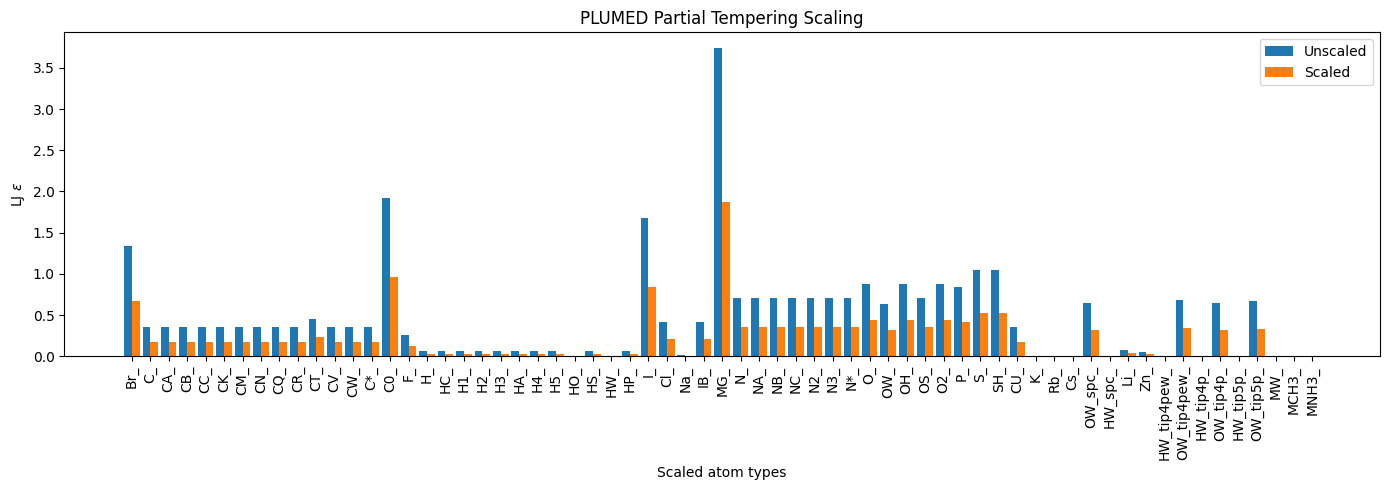

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def read_scaled_eps(topfile):

    rows = []

    with open(topfile) as f:

        for line in f:

            if "scaled" not in line:
                continue

            line = line.split(";")[0]

            parts = line.split()

            if len(parts) < 7:
                continue

            atom = parts[0]
            eps = float(parts[6])

            rows.append([atom, eps])

    return pd.DataFrame(
        rows,
        columns=["atom","epsilon"]
    )

top1 = read_scaled_eps("2a/scaled1.0.top")
top05 = read_scaled_eps("2a/scaled0.5.top")

df = top1.merge(
    top05,
    on="atom",
    suffixes=("_1.0","_0.5")
)

x = np.arange(len(df))

width = 0.42

plt.figure(figsize=(14,5))

plt.bar(
    x-width/2,
    df["epsilon_1.0"],
    width,
    label="Unscaled"
)

plt.bar(
    x+width/2,
    df["epsilon_0.5"],
    width,
    label="Scaled"
)

plt.xticks(
    x,
    df["atom"],
    rotation=90
)

plt.ylabel(r"LJ $\epsilon$")
plt.xlabel("Scaled atom types")

plt.title(
    "PLUMED Partial Tempering Scaling"
)

plt.legend()

plt.tight_layout()
plt.show()

# 2b: Sanity check on generated topologies

In [12]:
import os
import subprocess

def run_cmd(cmd):
    print(cmd)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

# ============================================================
# Exercise 2b: short reference trajectory sanity check
# ============================================================

os.makedirs("2b", exist_ok=True)

run_cmd(
    "cd 2b && "
    "gmx_mpi grompp "
    "-f ../grompp.mdp "
    "-c ../b4md.gro "
    "-p ../topol.top "
    "-o topol.tpr"
)

run_cmd(
    "cd 2b && "
    "gmx_mpi mdrun "
    "-deffnm topol "
    "-nsteps 5000"
)

print("\n🎉 Finished Exercise 2b reference trajectory.")

cd 2b && gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p ../topol.top -o topol.tpr


/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

Setting the LD random seed to -134885381

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 10853      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.439 nm between atom 3756 and 3764

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dime

/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en


🎉 Finished Exercise 2b reference trajectory.


### 🔍 Exercise 2b — Sanity Check

Recompute energies for the **same trajectory** using:

1. Original topology
2. `partial_tempering(1.0)` topology

```text
Same coordinates
+
Different topology files
↓
Compare energies
```



In [16]:
import os
import subprocess

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_"):
            os.environ.pop(k,None)

def run(cmd):
    clean_env()
    print(cmd)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

os.makedirs("2b/rerun0",exist_ok=True)
os.makedirs("2b/rerun1",exist_ok=True)

run("cp 2a/processed_selected.top 2b/processed_selected.top")

run("cd 2b && plumed partial_tempering 1.0 < processed_selected.top > topol_scaled1.0.top")

run("cd 2b && gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled1.0.top -o topol_scaled1.0.tpr")

run("cd 2b/rerun0 && gmx_mpi mdrun -rerun ../topol.xtc -s ../topol.tpr")

run('cd 2b/rerun0 && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no')

run("cd 2b/rerun1 && gmx_mpi mdrun -rerun ../topol.xtc -s ../topol_scaled1.0.tpr")

run('cd 2b/rerun1 && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no')

print("🎉 Finished sanity check")

cp 2a/processed_selected.top 2b/processed_selected.top
cd 2b && plumed partial_tempering 1.0 < processed_selected.top > topol_scaled1.0.top
cd 2b && gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled1.0.top -o topol_scaled1.0.tpr


               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2b
Command line:
  gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled1.0.top -o topol_scaled1.0.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file ../grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 11021.57
Number of degrees of freedom in T-Coupling group non-Protein is 65130.43

NOTE 2 [file ../grompp.mdp]:
  This run will generate roughly 3571 Mb of data


There were 2 NOTEs

Back Off! I just backed up topol_scaled1.0.tpr to ./#topol_scaled1.0.tpr.2

Setting the LD random seed to -42209330

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 10853      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.439 nm between atom 3756 and 3764

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimen

                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2b/rerun0
Command line:
  gmx_mpi mdrun -rerun ../topol.xtc -s ../topol.tpr

Reading file ../topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.
Changing nstlist from 10 to 80, rlist from 0.9 to 1.038


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do (non-perturbed) short-ranged interactions on the GPU
PP task will update and constrain coordinates on the CPU
PME tasks will do all aspects on the GPU
Using 1 MPI proce

cd 2b/rerun0 && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no


               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2b/rerun0
Command line:
  gmx_mpi energy -xvg no

Opened ener.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Disper.-corr. 
  9  Coulomb-(SR)    10  Coul.-recip.    11  Potential     

Last energy frame read 2 time   10.000            

GROMACS reminds you: "You see it through a charmed medium: you can not discern that the gilding is slime and the silk dra


Statistics over 5001 steps [ 0.0000 through 10.0000 ps ], 11 data sets
All statistics are over 3 points (frames)

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Bond                        3358.23         --    112.611   -85.0339  (kJ/mol)
Angle                        9202.7         --    80.8488     147.43  (kJ/mol)
Proper Dih.                 10557.3         --    93.4001   -150.444  (kJ/mol)
Per. Imp. Dih.              508.758         --    10.9514    24.9576  (kJ/mol)
LJ-14                       4397.46         --    27.8932    10.3525  (kJ/mol)
Coulomb-14                  53411.9         --    137.631    295.879  (kJ/mol)
LJ (SR)                     60736.6         --    635.955    1375.98  (kJ/mol)
Disper. corr.              -7052.44         --          0          0  (kJ/mol)
Coulomb (SR)                -609445         --    318.863   -708.188  (kJ/mol)
Coul. recip.             

                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2b/rerun1
Command line:
  gmx_mpi mdrun -rerun ../topol.xtc -s ../topol_scaled1.0.tpr

Reading file ../topol_scaled1.0.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.
Changing nstlist from 10 to 80, rlist from 0.9 to 1.038


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do (non-perturbed) short-ranged interactions on the GPU
PP task will update and constrain coordinates on the CPU
PME tasks will do all aspects on the G

cd 2b/rerun1 && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no

Statistics over 5001 steps [ 0.0000 through 10.0000 ps ], 11 data sets
All statistics are over 3 points (frames)

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Bond                        3358.23         --    112.611   -85.0339  (kJ/mol)
Angle                        9202.7         --    80.8488     147.43  (kJ/mol)
Proper Dih.                 10557.3         --    93.4001   -150.444  (kJ/mol)
Per. Imp. Dih.              508.758         --    10.9514    24.9576  (kJ/mol)
LJ-14                       4397.46         --    27.8932    10.3525  (kJ/mol)
Coulomb-14                  53411.9         --    137.631    295.879  (kJ/mol)
LJ (SR)                     60736.7         --    635.927    1375.92  (kJ/mol)
Disper. corr.              -7052.44         --          0          0  (kJ/mol)
Coulomb (SR)                -609

               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2b/rerun1
Command line:
  gmx_mpi energy -xvg no

Opened ener.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Disper.-corr. 
  9  Coulomb-(SR)    10  Coul.-recip.    11  Potential     

Last energy frame read 2 time   10.000            

GROMACS reminds you: "Gabba Gabba Hey!" (The Ramones)



Expected:

```text
Original − Scaled(1.0) ≈ 0
```

Tiny numerical noise is normal.

Confirms:

✅ `partial_tempering` edited the topology correctly  
✅ No force field terms were accidentally changed  
✅ Hamiltonian remains unchanged at λ = 1.0

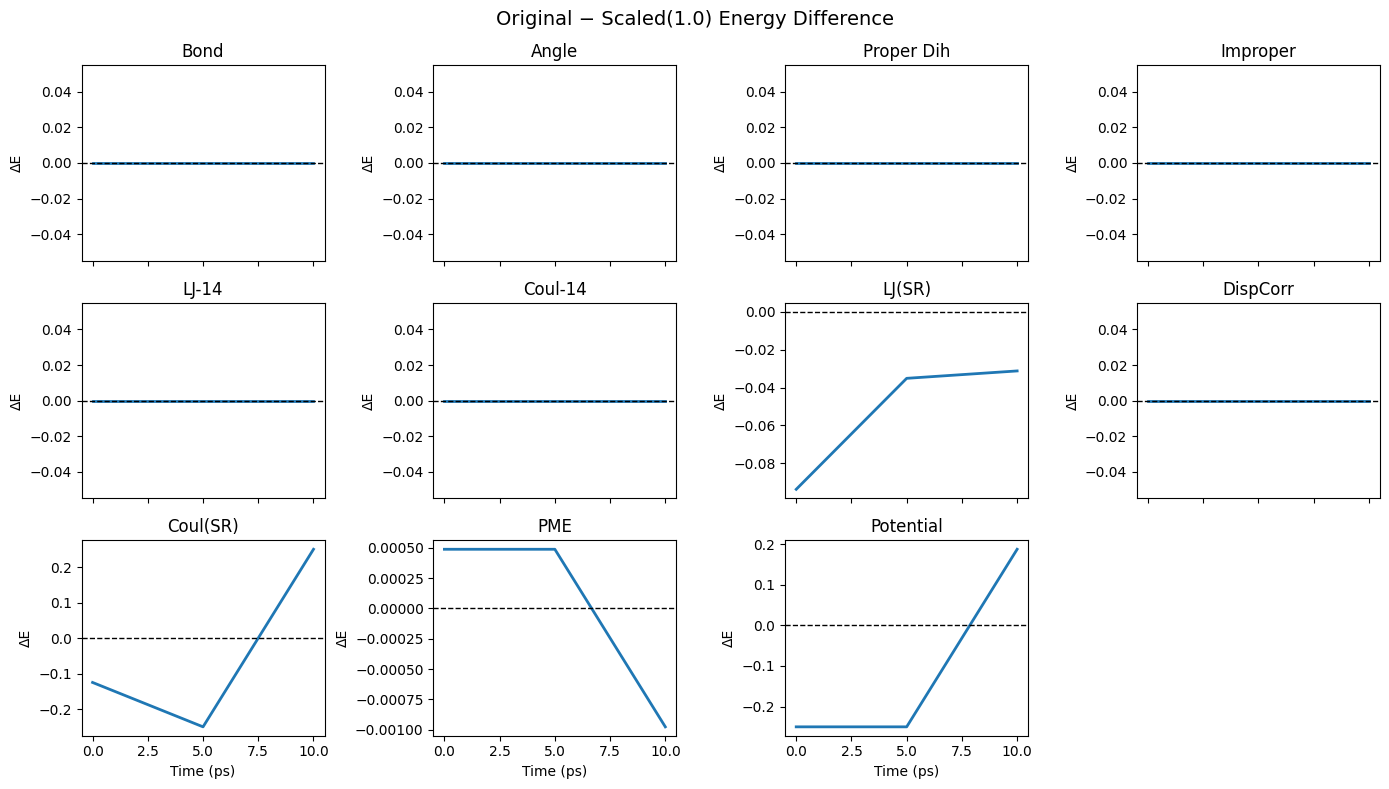

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

labels = [
    "Bond", "Angle", "Proper Dih", "Improper",
    "LJ-14", "Coul-14", "LJ(SR)", "DispCorr",
    "Coul(SR)", "PME", "Potential"
]

ene = pd.read_csv("2b/rerun0/energy.xvg", header=None, sep=r"\s+")
ene_scaled = pd.read_csv("2b/rerun1/energy.xvg", header=None, sep=r"\s+")

time = ene.iloc[:, 0]
diff = ene.iloc[:, 1:].values - ene_scaled.iloc[:, 1:].values

fig, axes = plt.subplots(3, 4, figsize=(14, 8), sharex=True)
axes = axes.flatten()

for i, name in enumerate(labels):
    axes[i].plot(time, diff[:, i], lw=2)
    axes[i].axhline(0, color="black", ls="--", lw=1)
    axes[i].set_title(name)
    axes[i].set_ylabel("ΔE")

for j in range(len(labels), len(axes)):
    axes[j].axis("off")

for ax in axes[-4:]:
    ax.set_xlabel("Time (ps)")

fig.suptitle("Original − Scaled(1.0) Energy Difference", fontsize=14)
plt.tight_layout()
plt.show()

### 🔍 Whole-System Scaling Check

Select all atoms (protein + water + ions), apply:

```text
partial_tempering(0.1)
```

Then recompute energies on the **same trajectory** using `-rerun`.

Expected:

```text
Dihedral ≈ 0.1×
LJ ≈ 0.1×
Coulomb ≈ 0.1×
```

Confirms:

✅ Whole-system Hamiltonian scaling works correctly

In [23]:
import os
import re
import subprocess

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_"):
            os.environ.pop(k,None)

def run(cmd):
    clean_env()
    print(cmd)
    subprocess.run(cmd, shell=True, executable="/bin/bash", check=True)

os.makedirs("2b/rerun_whole", exist_ok=True)

# mark ALL moleculetype [ atoms ] sections with "_"
with open("2a/processed.top") as f, open("2b/processed_selected_whole.top", "w") as ff:

    in_atoms = False

    for l in f:

        if in_atoms and not re.match(r" *;.*", l) and not re.match(r"\[.*", l) and len(l.split()) > 2:
            ll = l.split()
            ll[1] = ll[1] + "_"
            print(" ".join(ll), file=ff)
        else:
            print(l, end="", file=ff)

        if re.match(r"\[ *atoms *\]", l):
            in_atoms = True
        elif re.match(r"\[.*", l):
            in_atoms = False

run("cd 2b && plumed partial_tempering 0.1 < processed_selected_whole.top > topol_scaled_whole0.1.top")

run("cd 2b && gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled_whole0.1.top -o topol_scaled_whole0.1.tpr")

run("cd 2b/rerun_whole && gmx_mpi mdrun -rerun ../topol.xtc -s ../topol_scaled_whole0.1.tpr")

run('cd 2b/rerun_whole && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no')

print("🎉 Finished whole-system 0.1 scaling sanity check")

cd 2b && plumed partial_tempering 0.1 < processed_selected_whole.top > topol_scaled_whole0.1.top
cd 2b && gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled_whole0.1.top -o topol_scaled_whole0.1.tpr


               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2b
Command line:
  gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled_whole0.1.top -o topol_scaled_whole0.1.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file ../grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 11021.57
Number of degrees of freedom in T-Coupling group non-Protein is 65130.43

NOTE 2 [file ../grompp.mdp]:
  This run will generate roughly 3571 Mb of data


There were 2 NOTEs

GROMACS reminds you: "All that glitters may not be gold, but a

Setting the LD random seed to -140575002

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 10853      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.439 nm between atom 3756 and 3764

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.900 nm, buffer size 0.000 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dime

                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2b/rerun_whole
Command line:
  gmx_mpi mdrun -rerun ../topol.xtc -s ../topol_scaled_whole0.1.tpr

Reading file ../topol_scaled_whole0.1.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.
Changing nstlist from 10 to 100, rlist from 0.9 to 0.9


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do (non-perturbed) short-ranged interactions on the GPU
PP task will update and constrain coordinates on the CPU
PME tasks will do all 

cd 2b/rerun_whole && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no


               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2b/rerun_whole
Command line:
  gmx_mpi energy -xvg no

Opened ener.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Disper.-corr. 
  9  Coulomb-(SR)    10  Coul.-recip.    11  Potential     

Last energy frame read 2 time   10.000            

GROMACS reminds you: "Science is a wonderful thing if one does not have to earn one's living at it." (Albert Einstei


Statistics over 5001 steps [ 0.0000 through 10.0000 ps ], 11 data sets
All statistics are over 3 points (frames)

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Bond                        3358.23         --    112.611   -85.0339  (kJ/mol)
Angle                        9202.7         --    80.8488     147.43  (kJ/mol)
Proper Dih.                 1055.73         --    9.34011   -15.0443  (kJ/mol)
Per. Imp. Dih.              50.8758         --    1.09514    2.49576  (kJ/mol)
LJ-14                       439.746         --     2.7893    1.03516  (kJ/mol)
Coulomb-14                   5341.2         --    13.7627    29.5879  (kJ/mol)
LJ (SR)                     6073.67         --    63.5981    137.615  (kJ/mol)
Disper. corr.              -705.244         --          0          0  (kJ/mol)
Coulomb (SR)               -60944.4         --    31.9611   -71.1055  (kJ/mol)
Coul. recip.             

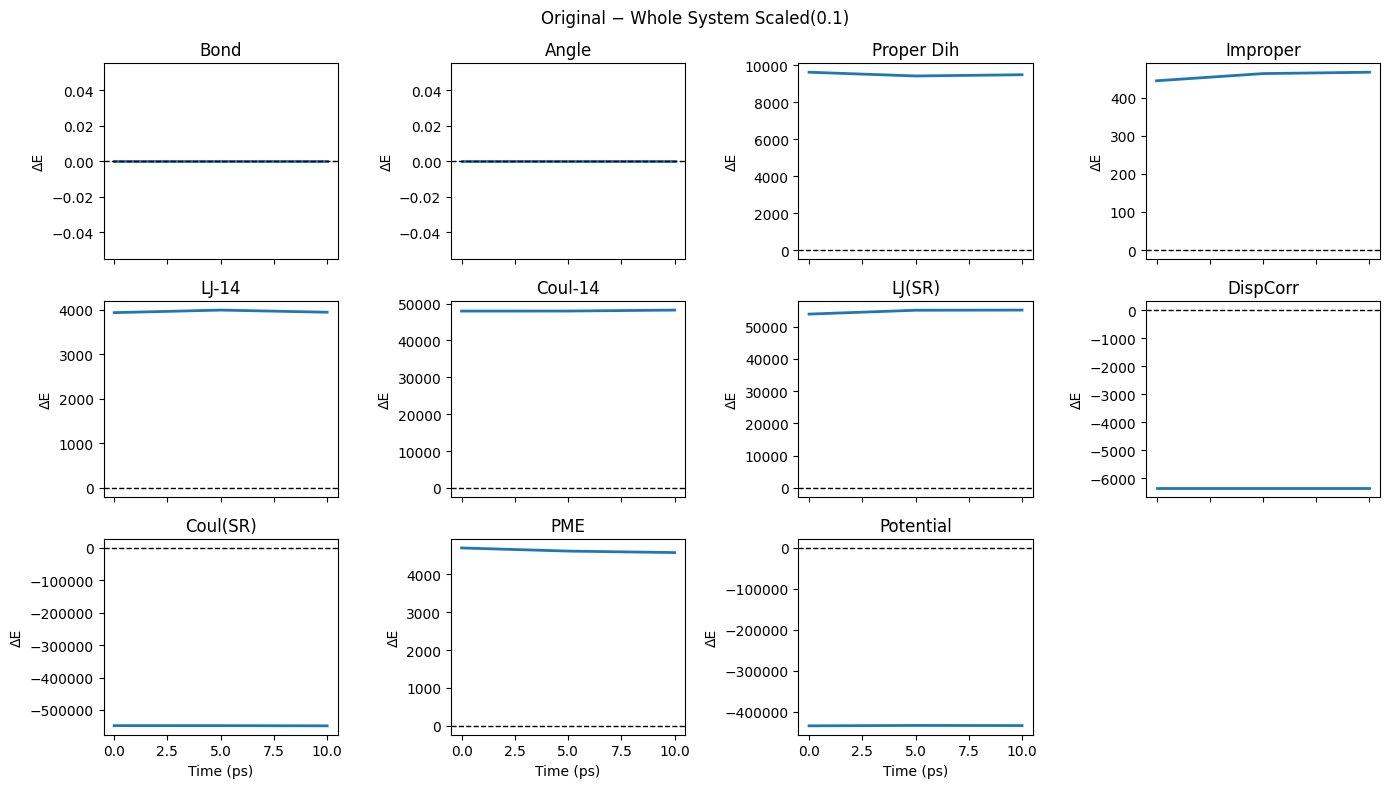

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

labels = [
    "Bond", "Angle", "Proper Dih", "Improper",
    "LJ-14", "Coul-14", "LJ(SR)", "DispCorr",
    "Coul(SR)", "PME", "Potential"
]

ene = pd.read_csv("2b/rerun0/energy.xvg", header=None, sep=r"\s+")
ene_scaled = pd.read_csv("2b/rerun_whole/energy.xvg", header=None, sep=r"\s+")

time = ene.iloc[:,0]
diff = ene.iloc[:,1:].values - ene_scaled.iloc[:,1:].values

fig, axes = plt.subplots(3,4,figsize=(14,8),sharex=True)
axes = axes.flatten()

for i,name in enumerate(labels):
    axes[i].plot(time,diff[:,i],lw=2)
    axes[i].axhline(0,color="black",ls="--",lw=1)
    axes[i].set_title(name)
    axes[i].set_ylabel("ΔE")

for j in range(len(labels),12):
    axes[j].axis("off")

for ax in axes[-4:]:
    ax.set_xlabel("Time (ps)")

fig.suptitle("Original − Whole System Scaled(0.1)")
plt.tight_layout()
plt.show()

### 🔍 Whole-System Scaling Check

Applied:

```text
partial_tempering(0.1)
```

Observed:

✅ Bond / Angle unchanged  
✅ Dihedral, LJ, Coulomb scaled  
✅ Potential changed strongly  

Inference:

```text
Whole-system Hamiltonian scaling works correctly
```

# 2c: Sanity check on replica-exchange implementation

Once we know the topologies are fine, we should double check if the gromacs+plumed implementation is correctly calculating the acceptance.

We run a replica exchange simulation with 2 replicas with identical Hamiltonians. Acceptance shoud be 1.

In [30]:
import os
import subprocess

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_"):
            os.environ.pop(k, None)

def run(cmd):
    clean_env()
    print(cmd)
    subprocess.run(cmd, shell=True, executable="/bin/bash", check=True)

os.makedirs("2c/rep0", exist_ok=True)
os.makedirs("2c/rep1", exist_ok=True)

open("2c/plumed.dat", "w").close()

run("cp 2b/topol_scaled1.0.top 2c/topol_scaled1.0.top")

run("cd 2c/rep0 && gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p ../../topol.top -o topol.tpr")

run("cd 2c/rep1 && gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p ../topol_scaled1.0.top -o topol.tpr")

run("cd 2c && mpirun --oversubscribe -np 2 gmx_mpi mdrun -nsteps 1000 -multidir rep0 rep1 -replex 200 -hrex -plumed ../plumed.dat -nb cpu -pme cpu -bonded cpu -ntomp 1")

cp 2b/topol_scaled1.0.top 2c/topol_scaled1.0.top
cd 2c/rep0 && gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p ../../topol.top -o topol.tpr


               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2c/rep0
Command line:
  gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p ../../topol.top -o topol.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file ../../grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 11021.57
Number of degrees of freedom in T-Coupling group non-Protein is 65130.43

NOTE 2 [file ../../grompp.mdp]:
  This run will generate roughly 3571 Mb of data


There were 2 NOTEs

Back Off! I just backed up topol.tpr to ./#topol.tpr.4#

GROMACS remind

Setting the LD random seed to -1392771129

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 10853      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.439 nm between atom 3756 and 3764

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dim

               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2c/rep1
Command line:
  gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p ../topol_scaled1.0.top -o topol.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file ../../grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 11021.57
Number of degrees of freedom in T-Coupling group non-Protein is 65130.43

NOTE 2 [file ../../grompp.mdp]:
  This run will generate roughly 3571 Mb of data


There were 2 NOTEs

Back Off! I just backed up topol.tpr to ./#topol.tpr.4#

GROMACS

Setting the LD random seed to -856053521

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 10853      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.439 nm between atom 3756 and 3764

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dime

                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2c
Command line:
  gmx_mpi mdrun -nsteps 1000 -multidir rep0 rep1 -replex 200 -hrex -plumed ../plumed.dat -nb cpu -pme cpu -bonded cpu -ntomp 1


Back Off! I just backed up md.log to ./#md.log.3#

Back Off! I just backed up md.log to ./#md.log.3#
Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI

In [31]:
logfile = "2c/rep0/md.log"

patterns = ["Repl", "dplumed"]

with open(logfile) as f:
    lines = f.readlines()

for pattern in patterns:
    print(f"\n===== {pattern} =====")
    for line in lines:
        if pattern == "dplumed":
            if line.startswith("dplumed"):
                print(line.rstrip())
        else:
            if pattern in line:
                print(line.rstrip())


===== Repl =====
Initializing Replica Exchange
Repl  There are 2 replicas:
Replica-exchange molecular dynamics method for protein folding
Replica exchange in temperature
Replica exchange interval: 200
Replica random seed: -37800986
Replica exchange information below: ex and x = exchange, pr = probability
Replica exchange at step 200 time 0.40000
Repl 0 <-> 1  dE_term =  0.000e+00 (kT)
Repl ex  0 x  1
Repl pr   1.0
Replica exchange at step 400 time 0.80000
Repl ex  0    1
Repl pr
Replica exchange at step 600 time 1.20000
Repl 0 <-> 1  dE_term = -0.000e+00 (kT)
Repl ex  0 x  1
Repl pr   1.0
Replica exchange at step 800 time 1.60000
Repl ex  0    1
Repl pr
Replica exchange statistics
Repl  4 attempts, 2 odd, 2 even
Repl  average probabilities:
Repl     0    1
Repl      1.0
Repl  number of exchanges:
Repl     0    1
Repl        2
Repl  average number of exchanges:
Repl     0    1
Repl      1.0
Repl        Empirical Transition Matrix
Repl       1       2
Repl  0.5000  0.5000  0
Repl  0.500

### 🔍 Replica Exchange Sanity Check

Observed:

✅ Exchange probability = 1.0  
✅ Exchanges accepted every attempt  
✅ dE_term ≈ 0 kT  
✅ dplumed ~ 10⁻⁶–10⁻⁸ kT  

Inference:

```text
Replica exchange acceptance is implemented correctly
```

Identical Hamiltonians give ~100% acceptance as expected.

## 🧪 Test λ Spacing and Potential-Energy Overlap

Prepares **30 λ replicas from 1.00 to 0.30** to test whether neighboring replicas show sufficient **potential-energy overlap** and to evaluate whether the chosen λ spacing is suitable for efficient replica exchange.

In [57]:
import os
import subprocess
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_"):
            os.environ.pop(k,None)

def run(cmd):
    clean_env()
    print(cmd,flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

lambdas = np.linspace(1.00,0.30,30)

os.makedirs("2d",exist_ok=True)

def prep_lambda(lam):

    label = int(round(lam*100))
    path = f"2d/lambda_{label}"

    os.makedirs(path,exist_ok=True)

    run(f"cp 2a/processed_selected.top {path}/processed_selected.top")

    run(
        f"cd {path} && "
        f"plumed partial_tempering {lam:.3f} < processed_selected.top > topol.top"
    )

    run(
        f"cd {path} && "
        f"gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p topol.top -o topol.tpr -maxwarn 1"
    )

    return f"✅ lambda_{label}"

workers=len(lambdas)

with ThreadPoolExecutor(max_workers=workers) as executor:

    futures=[
        executor.submit(prep_lambda,lam)
        for lam in lambdas
    ]

    for future in as_completed(futures):
        print(future.result(),flush=True)

print("🎉 Finished prep")

cp 2a/processed_selected.top 2d/lambda_100/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_54/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_98/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_95/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_93/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_88/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_90/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_86/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_83/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_81/processed_selected.top
cd 2d/lambda_98 && plumed partial_tempering 0.976 < processed_selected.top > topol.top
cp 2a/processed_selected.top 2d/lambda_78/processed_selected.top
cd 2d/lambda_95 && plumed partial_tempering 0.952 < processed_selected.top > topol.top
cp 2a/processed_selected.top 2d/lambda_76/processed_selected.top
cd 2d/lambda_93 && plumed partial_tempering 0

               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpiWorking dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_95

Command line:
  gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p topol.top -o topol.tpr -maxwarn 1
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_52

Command line:
  gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p topol.top -o topol.tpr -maxwarn 1

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file ../../grompp.mdp]:
  You have set rlist larger than the inte

Setting the LD random seed to -20984329

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

++++ PLEASE READ AND CITE THE FOLLOWING REFERENCE ++++
J. S. Hub, B. L. de Groot, H. Grubmueller, G. Groenhof
Quantifying Artifacts in Ewald Simulations of Inhomogeneous Systems with a Net
Charge
J. Chem. Theory Comput. 10 (2014) pp. 381-393
-------- -------- --- Thank You --- -------- --------

Setting the LD random seed to -276828170

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2

Number of degrees of freedom in T-Coupling group Protein is 11021.57
Number of degrees of freedom in T-Coupling group non-Protein is 65130.43

NOTE 2 [file topol.top, line 57639]:
  System has non-zero total charge: 0.060256
  Total charge should normally be an integer. See
  https://manual.gromacs.org/current/user-guide/floating-point.html
  for discussion on how close it should be to an integer.




WARNING 1 [file topol.top, line 57639]:
  You are using Ewald electrostatics in a system with net charge. This can
  lead to severe artifacts, such as ions moving into regions with low
  dielectric, due to the uniform background charge. We suggest to
  neutralize your system with counter ions, possibly in combination with a
  physiological salt concentration.

Number of degrees of freedom in T-Coupling group Protein is 11021.57
Number of degrees of freedom in T-Coupling group non-Protein is 65130.43
Number of degrees of freedom in T-Coupling group Protein is 11021.57
Number of degrees of 

Analysing residue names:
There are:   271    Protein residues
There are: 10853      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.439 nm between atom 3756 and 3764

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimensions for X Y Z
Using a fourier grid of 56x72x56, spacing 0.120 0.115 0.119

Estimate for the relative computational load of the PME mesh part: 0.30
Analysing residue names:
There are:   271    Protein residues
There are: 10853      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.439 nm between atom 3756 and 3764

Determining Verlet buffer for a tolerance

...

Setting the LD random seed to -1086336577

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

++++ PLEASE READ AND CITE THE FOLLOWING REFERENCE ++++
J. S. Hub, B. L. de Groot, H. Grubmueller, G. Groenhof
Quantifying Artifacts in Ewald Simulations of Inhomogeneous Systems with a Net
Charge
J. Chem. Theory Comput. 10 (2014) pp. 381-393
-------- -------- --- Thank You --- -------- --------

Setting the LD random seed to -537010193

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding


NOTE 3 [file ../../grompp.mdp]:
  This run will generate roughly 3571 Mb of data


There were 3 NOTEs

There was 1 WARNING

NOTE 3 [file ../../grompp.mdp]:
  This run will generate roughly 3571 Mb of data


There were 3 NOTEs

There was 1 WARNING

GROMACS reminds you: "It is disconcerting to reflect on the number of students we have flunked in chemistry for not knowing what we later found to be untrue." (Robert L. Weber)


GROMACS reminds you: "It is disconcerting to reflect on the number of students we have flunked in chemistry for not knowing what we later found to be untrue." (Robert L. Weber)

Number of degrees of freedom in T-Coupling group Protein is 11021.57
Number of degrees of freedom in T-Coupling group non-Protein is 65130.43

NOTE 2 [file topol.top, line 57639]:
  System has non-zero total charge: 2.050259
  Total charge should normally be an integer. See
  https://manual.gromacs.org/current/user-guide/floating-point.html
  for discussion on how close it should be to an in

Analysing residue names:
There are:   271    Protein residues
There are: 10853      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.439 nm between atom 3756 and 3764

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimensions for X Y Z
Using a fourier grid of 56x72x56, spacing 0.120 0.115 0.119

Estimate for the relative computational load of the PME mesh part: 0.30
Analysing residue names:
There are:   271    Protein residues
There are: 10853      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.439 nm between atom 3756 and 3764

Determining Verlet buffer for a tolerance


GROMACS reminds you: "It is disconcerting to reflect on the number of students we have flunked in chemistry for not knowing what we later found to be untrue." (Robert L. Weber)


NOTE 3 [file ../../grompp.mdp]:
  This run will generate roughly 3571 Mb of data


There were 3 NOTEs

There was 1 WARNING

NOTE 3 [file ../../grompp.mdp]:
  This run will generate roughly 3571 Mb of data


There were 3 NOTEs

There was 1 WARNING

NOTE 3 [file ../../grompp.mdp]:
  This run will generate roughly 3571 Mb of data


There were 3 NOTEs

There was 1 WARNING

GROMACS reminds you: "It is disconcerting to reflect on the number of students we have flunked in chemistry for not knowing what we later found to be untrue." (Robert L. Weber)


GROMACS reminds you: "It is disconcerting to reflect on the number of students we have flunked in chemistry for not knowing what we later found to be untrue." (Robert L. Weber)


GROMACS reminds you: "It is disconcerting to reflect on the number of students we have flu

Analysing residue names:
There are:   271    Protein residues
There are: 10853      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.439 nm between atom 3756 and 3764

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimensions for X Y Z
Using a fourier grid of 56x72x56, spacing 0.120 0.115 0.119

Estimate for the relative computational load of the PME mesh part: 0.30
Analysing residue names:
There are:   271    Protein residues
There are: 10853      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.439 nm between atom 3756 and 3764

Determining Verlet buffer for a tolerance

## 🚀 Run 10 ns HREMD Test Across All λ Replicas

Runs all **30 λ replicas simultaneously for 10 ns** using GROMACS `-multidir`, distributed across four GPUs. The resulting trajectories are used to evaluate **potential-energy overlap between neighboring λ replicas** and refine the λ spacing for the production HREMD setup.
> **Note:** We do not perform replica exchange because no `-replex` option is specified; it runs the 30 λ windows in parallel.

In [66]:
import os
import subprocess
import numpy as np

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run(cmd):
    clean_env()
    print(cmd, flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

lambdas = np.linspace(1.00, 0.30, 30)

dirs = []

for lam in lambdas:

    label = int(round(lam * 100))
    dirs.append(f"2d/lambda_{label}")

multidir = " ".join(dirs)

run(
    f"mpirun --oversubscribe -np 30 "
    f"gmx_mpi mdrun "
    f"-multidir {multidir} "
    f"-deffnm topol "
    f"-nsteps 5000000 "
    f"-nb gpu "
    f"-pme gpu "
    f"-bonded gpu "
    f"-gputasks "
    f"0000000000000000"
    f"1111111111111111"
    f"22222222222222"
    f"33333333333333 "
    f"-pin auto "
    f"-ntomp 1"
)

print("🎉 Finished all lambdas")

mpirun --oversubscribe -np 30 gmx_mpi mdrun -multidir 2d/lambda_100 2d/lambda_98 2d/lambda_95 2d/lambda_93 2d/lambda_90 2d/lambda_88 2d/lambda_86 2d/lambda_83 2d/lambda_81 2d/lambda_78 2d/lambda_76 2d/lambda_73 2d/lambda_71 2d/lambda_69 2d/lambda_66 2d/lambda_64 2d/lambda_61 2d/lambda_59 2d/lambda_57 2d/lambda_54 2d/lambda_52 2d/lambda_49 2d/lambda_47 2d/lambda_44 2d/lambda_42 2d/lambda_40 2d/lambda_37 2d/lambda_35 2d/lambda_32 2d/lambda_30 -deffnm topol -nsteps 5000000 -nb gpu -pme gpu -bonded gpu -gputasks 000000000000000011111111111111112222222222222233333333333333 -pin auto -ntomp 1


                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ
Command line:
  gmx_mpi mdrun -multidir 2d/lambda_100 2d/lambda_98 2d/lambda_95 2d/lambda_93 2d/lambda_90 2d/lambda_88 2d/lambda_86 2d/lambda_83 2d/lambda_81 2d/lambda_78 2d/lambda_76 2d/lambda_73 2d/lambda_71 2d/lambda_69 2d/lambda_66 2d/lambda_64 2d/lambda_61 2d/lambda_59 2d/lambda_57 2d/lambda_54 2d/lambda_52 2d/lambda_49 2d/lambda_47 2d/lambda_44 2d/lambda_42 2d/lambda_40 2d/lambda_37 2d/lambda_35 2d/lambda_32 2d/lambda_30 -deffnm topol -nsteps 5000000 -nb gpu -pme gpu -bonded gpu -gputasks 000000000000000011111111111111112222222222222233333333333333 -pin auto -ntomp 1


Back Off! I just backed up topol.log to ./#topol.log.1#

Back Off! I just backed up topol.log to ./#topol.log.1#

Back Off! I just backed up topol.lo

🎉 Finished all lambdas


## 📊 Assess Structural Stability Across λ Replicas

Calculates **RMSD** and **radius of gyration (Rg)** for all **30 λ replicas** from the 10 ns HREMD test. Because stronger tempering at lower λ values can destabilize the protein, these measurements are used to determine whether the replicas remain structurally reasonable and to identify λ values that produce excessive unfolding or expansion. Together with the **potential-energy overlap**, this helps define an appropriate λ range and spacing for the production HREMD simulation.

In [67]:
import os
import subprocess
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run_cmd(cmd):
    clean_env()
    print(cmd, flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

def analyze_lambda(lam):

    label = int(round(lam * 100))
    replica_dir = os.path.join(workdir, "2d", f"lambda_{label}")

    tpr = os.path.join(replica_dir, "topol.tpr")
    xtc = os.path.join(replica_dir, "topol.xtc")

    gyrate_xvg = os.path.join(replica_dir, "gyration.xvg")
    rmsd_xvg = os.path.join(replica_dir, "rmsd.xvg")

    if not os.path.exists(tpr):
        return f"❌ lambda_{label}: missing topol.tpr"

    if not os.path.exists(xtc):
        return f"❌ lambda_{label}: missing topol.xtc"

    print(f"▶️ Starting lambda_{label}", flush=True)

    run_cmd(
        f'printf "1\\n" | '
        f'gmx_mpi gyrate '
        f'-f "{xtc}" '
        f'-s "{tpr}" '
        f'-o "{gyrate_xvg}"'
    )

    run_cmd(
        f'printf "1\\n1\\n" | '
        f'gmx_mpi rms '
        f'-f "{xtc}" '
        f'-s "{tpr}" '
        f'-o "{rmsd_xvg}"'
    )

    return f"✅ Finished lambda_{label}"

# ============================================================
# Settings
# ============================================================

workdir = os.getcwd()

lambdas = np.linspace(1.00, 0.30, 30)

# Run all lambdas at once
max_workers = len(lambdas)

# ============================================================
# Run analysis in parallel
# ============================================================

with ThreadPoolExecutor(max_workers=max_workers) as executor:

    futures = [
        executor.submit(analyze_lambda, lam)
        for lam in lambdas
    ]

    for future in as_completed(futures):
        try:
            print(future.result(), flush=True)
        except Exception as e:
            print(f"❌ Error: {e}", flush=True)

print("\n🎉 Finished all parallel Rg and RMSD analysis.")

▶️ Starting lambda_90
▶️ Starting lambda_93
▶️ Starting lambda_83
▶️ Starting lambda_78
printf "1\n" | gmx_mpi gyrate -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_93/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_93/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_93/gyration.xvg"
▶️ Starting lambda_100
printf "1\n" | gmx_mpi gyrate -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_83/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_83/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_83/gyration.xvg"
printf "1\n" | gmx_mpi gyrate -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_78/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_78/topol.tpr" -o "/panfs/accrep

               :-) GROMACS - gmx gyrate, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ
Command line:
  gmx_mpi gyrate -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_81/topol.xtc -s /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_81/topol.tpr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_81/gyration.xvg

Reading file /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_81/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_81/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has 36986 elements
Group     1 (        Protein) has  4422 elements
Group  

Selected 1: 'Protein'
printf "1\n1\n" | gmx_mpi rms -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_81/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_81/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_81/rmsd.xvg"


Last frame       2000 time 10000.000   

GROMACS reminds you: "Oh My God ! It's the Funky Shit" (Beastie Boys)

Reading frame    1000 time 5000.000                    :-) GROMACS - gmx rms, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ
Command line:
  gmx_mpi rms -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_81/topol.xtc -s /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_81/topol.tpr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_81/rmsd.xvg

Reading file /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_81/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_81/topol.tpr, VERSION 20

Selected 1: 'Protein'
printf "1\n1\n" | gmx_mpi rms -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_83/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_83/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_83/rmsd.xvg"


...

Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_93
✅ Finished lambda_57
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_42


Last frame       2000 time 10000.000   
Reading frame    1900 time 9500.000   
GROMACS reminds you: "Ludwig Boltzmann, who spent much of his life studying statistical mechanics, died in 1906, by his own hand. Paul Ehrenfest, carrying on the same work, died similarly in 1933. Now it is our turn to study statistical mechanics. Perhaps it will be wise to approach the subject cautiously." (David Goodstein)

Last frame       2000 time 10000.000   
Last frame       2000 time 10000.000   
Reading frame    1900 time 9500.000   
GROMACS reminds you: "Ludwig Boltzmann, who spent much of his life studying statistical mechanics, died in 1906, by his own hand. Paul Ehrenfest, carrying on the same work, died similarly in 1933. Now it is our turn to study statistical mechanics. Perhaps it will be wise to approach the subject cautiously." (David Goodstein)


GROMACS reminds you: "Ludwig Boltzmann, who spent much of his life studying statistical mechanics, died in 1906, by his own hand. Paul Ehrenfest,

Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_71
✅ Finished lambda_61
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_40
✅ Finished lambda_88
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_37
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_59
✅ Finished lambda_54



GROMACS reminds you: "Ludwig Boltzmann, who spent much of his life studying statistical mechanics, died in 1906, by his own hand. Paul Ehrenfest, carrying on the same work, died similarly in 1933. Now it is our turn to study statistical mechanics. Perhaps it will be wise to approach the subject cautiously." (David Goodstein)

Last frame       2000 time 10000.000   

GROMACS reminds you: "Ludwig Boltzmann, who spent much of his life studying statistical mechanics, died in 1906, by his own hand. Paul Ehrenfest, carrying on the same work, died similarly in 1933. Now it is our turn to study statistical mechanics. Perhaps it will be wise to approach the subject cautiously." (David Goodstein)

Last frame       2000 time 10000.000   

GROMACS reminds you: "Ludwig Boltzmann, who spent much of his life studying statistical mechanics, died in 1906, by his own hand. Paul Ehrenfest, carrying on the same work, died similarly in 1933. Now it is our turn to study statistical mechanics. Perhaps it wi

✅ Finished lambda_98
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_49
✅ Finished lambda_30
✅ Finished lambda_86
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_64
✅ Finished lambda_52
✅ Finished lambda_69
✅ Finished lambda_95
✅ Finished lambda_73
✅ Finished lambda_32

🎉 Finished all parallel Rg and RMSD analysis.


## 📈 Visualize Structural Stability Across λ Replicas

Plots **RMSD** and **radius of gyration (Rg)** for all valid λ replicas over the 10 ns HREMD test. This provides a direct visual check for increasing structural distortion or expansion at lower λ values and helps identify an appropriate tempering range for production HREMD.

Valid lambdas: [100, 98, 95, 93, 90, 88, 86, 83, 81, 78, 76, 73, 71, 69, 66, 64, 61, 59, 57, 54, 52, 49, 47, 44, 42, 40, 37, 35, 32, 30]


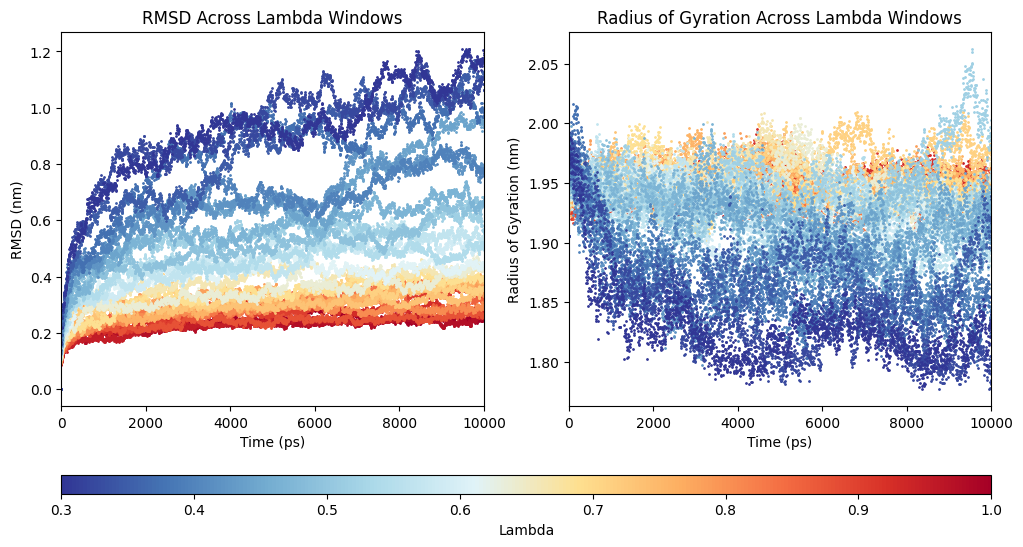

In [68]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.gridspec import GridSpec

# =========================================================
# COLORS
# =========================================================

BASE_COLORS = [
    "#313695", "#4575b4", "#74add1", "#abd9e9", "#e0f3f8",
    "#fee090", "#fdae61", "#f46d43", "#d73027", "#a50026"
]

CMAP = LinearSegmentedColormap.from_list("seq", BASE_COLORS, 256)

# =========================================================
# LAMBDAS
# =========================================================

lambdas = np.linspace(1.00, 0.30, 30)
labels = [int(round(lam * 100)) for lam in lambdas]

norm = Normalize(vmin=min(lambdas), vmax=max(lambdas))

main_dir = "2d"

# =========================================================
# XVG READER
# =========================================================

def read_xvg(filename):

    data = []

    with open(filename) as f:
        for line in f:
            line = line.strip()

            if not line:
                continue

            if line.startswith("@") or line.startswith("#"):
                continue

            try:
                data.append([float(x) for x in line.split()])
            except ValueError:
                continue

    return pd.DataFrame(data)

# =========================================================
# LOAD DATA
# =========================================================

rmsd_data = []
rg_data = []
valid_lambdas = []
valid_labels = []

for lam, label in zip(lambdas, labels):

    rmsd_file = os.path.join(main_dir, f"lambda_{label}", "rmsd.xvg")
    rg_file   = os.path.join(main_dir, f"lambda_{label}", "gyration.xvg")

    if not os.path.exists(rmsd_file):
        print(f"❌ Missing: {rmsd_file}")
        continue

    if not os.path.exists(rg_file):
        print(f"❌ Missing: {rg_file}")
        continue

    rmsd_df = read_xvg(rmsd_file)
    rg_df = read_xvg(rg_file)

    if rmsd_df.empty or rg_df.empty:
        print(f"⚠️ Empty XVG for lambda_{label}")
        continue

    rmsd_data.append(rmsd_df)
    rg_data.append(rg_df)
    valid_lambdas.append(lam)
    valid_labels.append(label)

print("Valid lambdas:", valid_labels)

# =========================================================
# FIGURE
# =========================================================

fig = plt.figure(figsize=(12, 6))

gs = GridSpec(
    2,
    2,
    height_ratios=[1, 0.05],
    hspace=0.35
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
cbar_ax = fig.add_subplot(gs[1, :])

# =========================================================
# RMSD
# =========================================================

for i, lam in enumerate(valid_lambdas):

    color = CMAP(norm(lam))

    ax1.plot(
        rmsd_data[i][0],
        rmsd_data[i][1],
        ".",
        color=color,
        markersize=2
    )

ax1.set_xlabel("Time (ps)")
ax1.set_ylabel("RMSD (nm)")
ax1.set_title("RMSD Across Lambda Windows")
ax1.set_xlim(0, 10000)

# =========================================================
# Rg
# =========================================================

for i, lam in enumerate(valid_lambdas):

    color = CMAP(norm(lam))

    ax2.plot(
        rg_data[i][0],
        rg_data[i][1],
        ".",
        color=color,
        markersize=2
    )

ax2.set_xlabel("Time (ps)")
ax2.set_ylabel("Radius of Gyration (nm)")
ax2.set_title("Radius of Gyration Across Lambda Windows")
ax2.set_xlim(0, 10000)

# =========================================================
# COLORBAR
# =========================================================

sm = ScalarMappable(norm=norm, cmap=CMAP)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    cax=cbar_ax,
    orientation="horizontal"
)

cbar.set_label("Lambda")

# =========================================================
# OUTPUT
# =========================================================

plt.show()

## ⚡ Extract Potential Energy Across λ Replicas

Extracts the **potential energy time series** from each of the 30 λ replicas. These distributions are used to assess **potential-energy overlap between neighboring λ windows**, helping determine whether the chosen λ spacing is suitable for efficient replica exchange.

In [70]:
import os
import subprocess
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed

# ============================================================
# Parallel Potential Energy Extraction
#   Input:  2d/lambda_XXX/topol.edr
#   Output: 2d/lambda_XXX/potential.xvg
# ============================================================

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run_cmd(cmd):
    clean_env()
    print(cmd, flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

def extract_potential(lam):

    label = int(round(lam * 100))
    replica_dir = os.path.join(main_dir, f"lambda_{label}")

    edr_file = os.path.join(replica_dir, "topol.edr")
    out_xvg  = os.path.join(replica_dir, "potential.xvg")

    if not os.path.exists(edr_file):
        return f"❌ lambda_{label}: missing topol.edr"

    print(f"▶️ Starting lambda_{label}", flush=True)

    cmd = (
        f'echo "Potential" | '
        f'gmx_mpi energy '
        f'-f "{edr_file}" '
        f'-o "{out_xvg}" '
        f'-xvg none'
    )

    run_cmd(cmd)

    data = np.loadtxt(out_xvg)

    if data.ndim == 1:
        n_frames = 1
    else:
        n_frames = data.shape[0]

    return f"✅ lambda_{label}: potential.xvg written, {n_frames} frames"

# ============================================================
# Settings
# ============================================================

workdir = os.getcwd()
main_dir = os.path.join(workdir, "2d")

lambdas = np.linspace(1.00, 0.30, 30)

# Run all lambda windows at once
max_workers = len(lambdas)

# ============================================================
# Run in parallel
# ============================================================

with ThreadPoolExecutor(max_workers=max_workers) as executor:

    futures = [
        executor.submit(extract_potential, lam)
        for lam in lambdas
    ]

    for future in as_completed(futures):
        try:
            print(future.result(), flush=True)
        except Exception as e:
            print(f"❌ Error: {e}", flush=True)

print("\n🎉 Finished extracting potential energy for all lambda windows.")

▶️ Starting lambda_100
▶️ Starting lambda_98
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_100/topol.edr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_100/potential.xvg" -xvg none
▶️ Starting lambda_95
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_95/topol.edr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_95/potential.xvg" -xvg none
▶️ Starting lambda_93
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_93/topol.edr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_93/potential.xvg" -xvg none
▶️ Starting lambda_90
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_98/topol.edr" -o "/panfs/accrepfs.vampire/da

               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ
Command line:
  gmx_mpi energy -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_47/topol.edr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_47/potential.xvg -xvg none

Opened /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_47/topol.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  


Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -442862         18    738.296    57.3652  (kJ/mol)

Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -456246         24    741.266   -149.585  (kJ/mol)

Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -463632         31    

               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ
Command line:
  gmx_mpi energy -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_64/topol.edr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_64/potential.xvg -xvg none

Opened /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_64/topol.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  


Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -457458         22    742.405   -7.38592  (kJ/mol)
✅ lambda_88: potential.xvg written, 1001 frames

Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -466192         44    746.706   -249.877  (kJ/mol)
✅ lambda_73: potential.xvg written, 1001 frames
✅ lambda_64: potential.xvg written, 1001 frames
✅ lambda_76: potential.xvg written, 1001 frames

Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy 

...

✅ lambda_57: potential.xvg written, 1001 frames

Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -459951         33    736.564   -190.472  (kJ/mol)

Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -448925         16    747.833    8.63087  (kJ/mol)
✅ lambda_81: potential.xvg written, 1001 frames
✅ lambda_59: potential.xvg written, 1001 frames

Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RM

Last energy frame read 1000 time 10000.000         

GROMACS reminds you: "Right Now My Job is Eating These Doughnuts" (Bodycount)

               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ
Command line:
  gmx_mpi energy -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_35/topol.edr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_35/potential.xvg -xvg none

Opened /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_35/topol.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------

✅ lambda_35: potential.xvg written, 1001 frames

Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -440431         17    738.048    87.2484  (kJ/mol)
✅ lambda_42: potential.xvg written, 1001 frames

Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -453767         15    737.472    13.0021  (kJ/mol)
✅ lambda_69: potential.xvg written, 1001 frames

Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RM


GROMACS reminds you: "Right Now My Job is Eating These Doughnuts" (Bodycount)

Last energy frame read 1000 time 10000.000         

GROMACS reminds you: "Right Now My Job is Eating These Doughnuts" (Bodycount)

               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ
Command line:
  gmx_mpi energy -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_83/topol.edr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_83/potential.xvg -xvg none

Opened /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_83/topol.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an emp

✅ lambda_40: potential.xvg written, 1001 frames
✅ lambda_71: potential.xvg written, 1001 frames

Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -444030         31    742.499   -150.032  (kJ/mol)
✅ lambda_37: potential.xvg written, 1001 frames
✅ lambda_44: potential.xvg written, 1001 frames
✅ lambda_52: potential.xvg written, 1001 frames
✅ lambda_32: potential.xvg written, 1001 frames
✅ lambda_49: potential.xvg written, 1001 frames
✅ lambda_95: potential.xvg written, 1001 frames
✅ lambda_90: potential.xvg written, 1001 frames

🎉 Finished extracting potential energy for all lambda windows.


## ⚡ Evaluate Potential-Energy Overlap Between λ Replicas

Plots the **potential-energy distributions** from the 10 ns HREMD test for all 30 λ replicas. Overlap between neighboring distributions is used to evaluate whether the **λ spacing provides sufficient energetic overlap for replica exchange** and to guide selection of the final λ schedule.

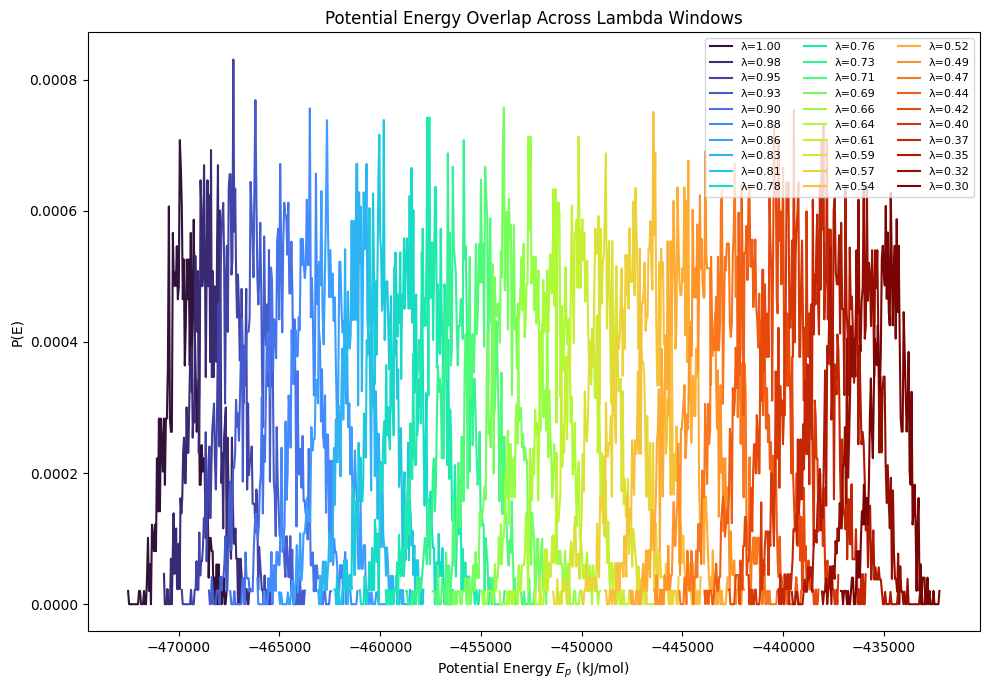

In [71]:
import os
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Plot Potential Energy Overlap
#   Input:  2d/lambda_XXX/potential.xvg
# ============================================================

main_dir = "2d"

lambdas = np.linspace(1.00, 0.30, 30)
labels = [int(round(lam * 100)) for lam in lambdas]

cmap = plt.cm.turbo
colors = cmap(np.linspace(0, 1, len(lambdas)))

plt.figure(figsize=(10, 7))

for i, (lam, label) in enumerate(zip(lambdas, labels)):

    pot_file = os.path.join(main_dir, f"lambda_{label}", "potential.xvg")

    if not os.path.exists(pot_file):
        print(f"❌ Missing: {pot_file}")
        continue

    data = np.loadtxt(pot_file)

    if data.ndim == 1:
        continue

    time = data[:, 0]
    pot = data[:, 1]

    pdf, edges = np.histogram(
        pot,
        bins=100,
        density=True
    )

    bin_centers = 0.5 * (edges[:-1] + edges[1:])

    plt.plot(
        bin_centers,
        pdf,
        color=colors[i],
        lw=1.5,
        label=f"λ={lam:.2f}"
    )

plt.xlabel(r"Potential Energy $E_p$ (kJ/mol)")
plt.ylabel("P(E)")
plt.title("Potential Energy Overlap Across Lambda Windows")
plt.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

### 🔎 Initial Assessment

From the initial 10 ns test, the **potential-energy distributions are noisy and their overlap is difficult to evaluate clearly**, while the **RMSD and Rg trajectories have not yet reached stable plateaus**. Based on these results, the simulations will be extended and the same analyses repeated after additional sampling.
*******

## ⏳ Extend the HREMD Test to 100 ns

Continues all **30 λ replicas from the existing checkpoints** for an additional **90 ns**, bringing the total sampling time to **100 ns per replica**. The extended trajectories will be used to reassess **RMSD, radius of gyration, and potential-energy overlap** after longer sampling.
> **Note:** We do not perform replica exchange because no `-replex` option is specified; it runs the 30 λ windows in parallel.

In [ ]:
import os
import subprocess
import numpy as np

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run(cmd):
    clean_env()
    print(cmd, flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

lambdas = np.linspace(1.00, 0.30, 30)

dirs = []

for lam in lambdas:
    label = int(round(lam * 100))
    dirs.append(f"2d/lambda_{label}")

multidir = " ".join(dirs)

run(
    f"mpirun --oversubscribe -np 30 "
    f"gmx_mpi mdrun "
    f"-multidir {multidir} "
    f"-deffnm topol "
    f"-cpi topol.cpt "
    f"-append "
    f"-nsteps 45000000 "
    f"-nb gpu "
    f"-pme gpu "
    f"-bonded gpu "
    f"-gputasks "
    f"0000000000000000"
    f"1111111111111111"
    f"22222222222222"
    f"33333333333333 "
    f"-pin auto "
    f"-ntomp 1"
)

print("🎉 Continued all lambdas by 90 ns")

mpirun --oversubscribe -np 30 gmx_mpi mdrun -multidir 2d/lambda_100 2d/lambda_98 2d/lambda_95 2d/lambda_93 2d/lambda_90 2d/lambda_88 2d/lambda_86 2d/lambda_83 2d/lambda_81 2d/lambda_78 2d/lambda_76 2d/lambda_73 2d/lambda_71 2d/lambda_69 2d/lambda_66 2d/lambda_64 2d/lambda_61 2d/lambda_59 2d/lambda_57 2d/lambda_54 2d/lambda_52 2d/lambda_49 2d/lambda_47 2d/lambda_44 2d/lambda_42 2d/lambda_40 2d/lambda_37 2d/lambda_35 2d/lambda_32 2d/lambda_30 -deffnm topol -cpi topol.cpt -append -nsteps 45000000 -nb gpu -pme gpu -bonded gpu -gputasks 000000000000000011111111111111112222222222222233333333333333 -pin auto -ntomp 1


                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ
Command line:
  gmx_mpi mdrun -multidir 2d/lambda_100 2d/lambda_98 2d/lambda_95 2d/lambda_93 2d/lambda_90 2d/lambda_88 2d/lambda_86 2d/lambda_83 2d/lambda_81 2d/lambda_78 2d/lambda_76 2d/lambda_73 2d/lambda_71 2d/lambda_69 2d/lambda_66 2d/lambda_64 2d/lambda_61 2d/lambda_59 2d/lambda_57 2d/lambda_54 2d/lambda_52 2d/lambda_49 2d/lambda_47 2d/lambda_44 2d/lambda_42 2d/lambda_40 2d/lambda_37 2d/lambda_35 2d/lambda_32 2d/lambda_30 -deffnm topol -cpi topol.cpt -append -nsteps 45000000 -nb gpu -pme gpu -bonded gpu -gputasks 000000000000000011111111111111112222222222222233333333333333 -pin auto -ntomp 1

Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (si

## 📊 Recalculate RMSD and Radius of Gyration After 100 ns

Recalculates **RMSD** and **radius of gyration (Rg)** for all **30 λ replicas** using the extended 100 ns trajectories. These updated measurements are used to reassess structural stability and determine whether the replicas have reached more stable behavior after longer sampling.

In [5]:
import os
import subprocess
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run_cmd(cmd):
    clean_env()
    print(cmd, flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

def analyze_lambda(lam):

    label = int(round(lam * 100))
    replica_dir = os.path.join(workdir, "2d", f"lambda_{label}")

    tpr = os.path.join(replica_dir, "topol.tpr")
    xtc = os.path.join(replica_dir, "topol.xtc")

    gyrate_xvg = os.path.join(replica_dir, "gyration.xvg")
    rmsd_xvg = os.path.join(replica_dir, "rmsd.xvg")

    if not os.path.exists(tpr):
        return f"❌ lambda_{label}: missing topol.tpr"

    if not os.path.exists(xtc):
        return f"❌ lambda_{label}: missing topol.xtc"

    print(f"▶️ Starting lambda_{label}", flush=True)

    run_cmd(
        f'printf "1\\n" | '
        f'gmx_mpi gyrate '
        f'-f "{xtc}" '
        f'-s "{tpr}" '
        f'-o "{gyrate_xvg}"'
    )

    run_cmd(
        f'printf "1\\n1\\n" | '
        f'gmx_mpi rms '
        f'-f "{xtc}" '
        f'-s "{tpr}" '
        f'-o "{rmsd_xvg}"'
    )

    return f"✅ Finished lambda_{label}"

# ============================================================
# Settings
# ============================================================

workdir = os.getcwd()

lambdas = np.linspace(1.00, 0.30, 30)

# Run all lambdas at once
max_workers = len(lambdas)

# ============================================================
# Run analysis in parallel
# ============================================================

with ThreadPoolExecutor(max_workers=max_workers) as executor:

    futures = [
        executor.submit(analyze_lambda, lam)
        for lam in lambdas
    ]

    for future in as_completed(futures):
        try:
            print(future.result(), flush=True)
        except Exception as e:
            print(f"❌ Error: {e}", flush=True)

print("\n🎉 Finished all parallel Rg and RMSD analysis.")

▶️ Starting lambda_76
printf "1\n" | gmx_mpi gyrate -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_76/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_76/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_76/gyration.xvg"


               :-) GROMACS - gmx gyrate, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ
Command line:
  gmx_mpi gyrate -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_76/topol.xtc -s /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_76/topol.tpr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_76/gyration.xvg

Reading file /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_76/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_76/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has 36986 elements
Group     1 (        Protein) has  4422 elements
Group  

▶️ Starting lambda_54
printf "1\n" | gmx_mpi gyrate -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_54/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_54/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_54/gyration.xvg"


Reading frame      50 time  250.000   

▶️ Starting lambda_57
printf "1\n" | gmx_mpi gyrate -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_57/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_57/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_57/gyration.xvg"
▶️ Starting lambda_37
printf "1\n" | gmx_mpi gyrate -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_37/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_37/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_37/gyration.xvg"
▶️ Starting lambda_66
printf "1\n" | gmx_mpi gyrate -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_66/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_66/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary

...

Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_83
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_32
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_49
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_86
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_88
✅ Finished lambda_52



GROMACS reminds you: "It Doesn't Have to Be Tip Top" (Pulp Fiction)

Last frame      20000 time 100000.000   

Back Off! I just backed up /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_86/rmsd.xvg to /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_86/#rmsd.xvg.1#
Last frame      20000 time 100000.000   

Back Off! I just backed up /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_88/rmsd.xvg to /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_88/#rmsd.xvg.1#
Last frame      20000 time 100000.000   

Back Off! I just backed up /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_52/rmsd.xvg to /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_52/#rmsd.xvg.1#

GROMACS reminds you: "It Doesn't Have to Be Tip Top" (Pulp Fiction)


GROMACS reminds you: "It Doesn't Have to Be Tip Top" (Pulp Fiction)


GROMACS reminds

Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_44
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_59


Last frame      20000 time 100000.000   

Back Off! I just backed up /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_59/rmsd.xvg to /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_59/#rmsd.xvg.1#
Last frame      20000 time 100000.000   

Back Off! I just backed up /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_69/rmsd.xvg to /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_69/#rmsd.xvg.1#

GROMACS reminds you: "The best model of a cat is another cat..., specially the same cat." (Arturo Rosenblueth)

Last frame      20000 time 100000.000   
Last frame      20000 time 100000.000   

Back Off! I just backed up /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_95/rmsd.xvg to /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_95/#rmsd.xvg.1#

Back Off! I just backed up /panfs/accrepfs.vampire/data/kojetin_lab/HRE

Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_100
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_95
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_69
✅ Finished lambda_30
✅ Finished lambda_42
✅ Finished lambda_90

🎉 Finished all parallel Rg and RMSD analysis.


## 📈 Replot RMSD and Radius of Gyration After 100 ns

Plots the updated **RMSD** and **radius of gyration (Rg)** trajectories for all **30 λ replicas** over the full **100 ns** test. This is used to reassess whether each replica has reached a stable plateau and whether stronger tempering at lower λ values leads to excessive structural deviation or expansion.

Valid lambdas: [100, 98, 95, 93, 90, 88, 86, 83, 81, 78, 76, 73, 71, 69, 66, 64, 61, 59, 57, 54, 52, 49, 47, 44, 42, 40, 37, 35, 32, 30]


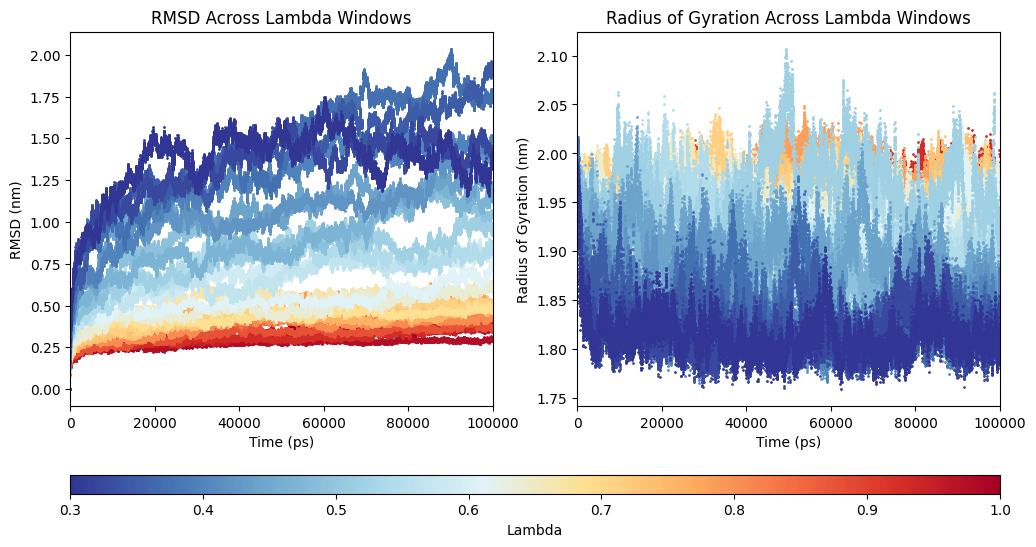

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.gridspec import GridSpec

# =========================================================
# COLORS
# =========================================================

BASE_COLORS = [
    "#313695", "#4575b4", "#74add1", "#abd9e9", "#e0f3f8",
    "#fee090", "#fdae61", "#f46d43", "#d73027", "#a50026"
]

CMAP = LinearSegmentedColormap.from_list("seq", BASE_COLORS, 256)

# =========================================================
# LAMBDAS
# =========================================================

lambdas = np.linspace(1.00, 0.30, 30)
labels = [int(round(lam * 100)) for lam in lambdas]

norm = Normalize(vmin=min(lambdas), vmax=max(lambdas))

main_dir = "2d"

# =========================================================
# XVG READER
# =========================================================

def read_xvg(filename):

    data = []

    with open(filename) as f:
        for line in f:
            line = line.strip()

            if not line:
                continue

            if line.startswith("@") or line.startswith("#"):
                continue

            try:
                data.append([float(x) for x in line.split()])
            except ValueError:
                continue

    return pd.DataFrame(data)

# =========================================================
# LOAD DATA
# =========================================================

rmsd_data = []
rg_data = []
valid_lambdas = []
valid_labels = []

for lam, label in zip(lambdas, labels):

    rmsd_file = os.path.join(main_dir, f"lambda_{label}", "rmsd.xvg")
    rg_file   = os.path.join(main_dir, f"lambda_{label}", "gyration.xvg")

    if not os.path.exists(rmsd_file):
        print(f"❌ Missing: {rmsd_file}")
        continue

    if not os.path.exists(rg_file):
        print(f"❌ Missing: {rg_file}")
        continue

    rmsd_df = read_xvg(rmsd_file)
    rg_df = read_xvg(rg_file)

    if rmsd_df.empty or rg_df.empty:
        print(f"⚠️ Empty XVG for lambda_{label}")
        continue

    rmsd_data.append(rmsd_df)
    rg_data.append(rg_df)
    valid_lambdas.append(lam)
    valid_labels.append(label)

print("Valid lambdas:", valid_labels)

# =========================================================
# FIGURE
# =========================================================

fig = plt.figure(figsize=(12, 6))

gs = GridSpec(
    2,
    2,
    height_ratios=[1, 0.05],
    hspace=0.35
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
cbar_ax = fig.add_subplot(gs[1, :])

# =========================================================
# RMSD
# =========================================================

for i, lam in enumerate(valid_lambdas):

    color = CMAP(norm(lam))

    ax1.plot(
        rmsd_data[i][0],
        rmsd_data[i][1],
        ".",
        color=color,
        markersize=2
    )

ax1.set_xlabel("Time (ps)")
ax1.set_ylabel("RMSD (nm)")
ax1.set_title("RMSD Across Lambda Windows")
ax1.set_xlim(0, 100000)

# =========================================================
# Rg
# =========================================================

for i, lam in enumerate(valid_lambdas):

    color = CMAP(norm(lam))

    ax2.plot(
        rg_data[i][0],
        rg_data[i][1],
        ".",
        color=color,
        markersize=2
    )

ax2.set_xlabel("Time (ps)")
ax2.set_ylabel("Radius of Gyration (nm)")
ax2.set_title("Radius of Gyration Across Lambda Windows")
ax2.set_xlim(0, 100000)

# =========================================================
# COLORBAR
# =========================================================

sm = ScalarMappable(norm=norm, cmap=CMAP)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    cax=cbar_ax,
    orientation="horizontal"
)

cbar.set_label("Lambda")

# =========================================================
# OUTPUT
# =========================================================

plt.show()

## ⚡ Re-extract Potential Energy After 100 ns

Extracts the **potential-energy time series** for all **30 λ replicas** from the extended **100 ns trajectories**. These updated data are used to re-evaluate **potential-energy overlap between neighboring λ replicas** after longer sampling.

In [8]:
import os
import subprocess
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed

# ============================================================
# Parallel Potential Energy Extraction
#   Input:  2d/lambda_XXX/topol.edr
#   Output: 2d/lambda_XXX/potential.xvg
# ============================================================

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run_cmd(cmd):
    clean_env()
    print(cmd, flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

def extract_potential(lam):

    label = int(round(lam * 100))
    replica_dir = os.path.join(main_dir, f"lambda_{label}")

    edr_file = os.path.join(replica_dir, "topol.edr")
    out_xvg  = os.path.join(replica_dir, "potential.xvg")

    if not os.path.exists(edr_file):
        return f"❌ lambda_{label}: missing topol.edr"

    print(f"▶️ Starting lambda_{label}", flush=True)

    cmd = (
        f'echo "Potential" | '
        f'gmx_mpi energy '
        f'-f "{edr_file}" '
        f'-o "{out_xvg}" '
        f'-xvg none'
    )

    run_cmd(cmd)

    data = np.loadtxt(out_xvg)

    if data.ndim == 1:
        n_frames = 1
    else:
        n_frames = data.shape[0]

    return f"✅ lambda_{label}: potential.xvg written, {n_frames} frames"

# ============================================================
# Settings
# ============================================================

workdir = os.getcwd()
main_dir = os.path.join(workdir, "2d")

lambdas = np.linspace(1.00, 0.30, 30)

# Run all lambda windows at once
max_workers = len(lambdas)

# ============================================================
# Run in parallel
# ============================================================

with ThreadPoolExecutor(max_workers=max_workers) as executor:

    futures = [
        executor.submit(extract_potential, lam)
        for lam in lambdas
    ]

    for future in as_completed(futures):
        try:
            print(future.result(), flush=True)
        except Exception as e:
            print(f"❌ Error: {e}", flush=True)

print("\n🎉 Finished extracting potential energy for all lambda windows.")

▶️ Starting lambda_100
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_100/topol.edr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_100/potential.xvg" -xvg none
▶️ Starting lambda_98
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_98/topol.edr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_98/potential.xvg" -xvg none▶️ Starting lambda_93

echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_93/topol.edr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_93/potential.xvg" -xvg none
▶️ Starting lambda_90
▶️ Starting lambda_95
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_95/topol.edr" -o "/panfs/accrepfs.vampire/da

               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ
Command line:
  gmx_mpi energy -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_88/topol.edr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_88/potential.xvg -xvg none

Opened /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_88/topol.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  


Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -463668        7.6    739.017   -6.43101  (kJ/mol)

Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -468768         28    741.731   -135.581  (kJ/mol)


Last energy frame read 10000 time 100000.000         
               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ
Command line:
  gmx_mpi energy -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_42/topol.edr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_42/potential.xvg -xvg none


GROMACS reminds you: "I don’t think we’re afraid of inline assembly." (Szilard Pall)

Opened /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_42/topol.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
----------------------------------------------------


Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -450126        8.6    737.145   -46.0929  (kJ/mol)


...

✅ lambda_59: potential.xvg written, 10001 frames

Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -464968         25     740.64   -64.4256  (kJ/mol)
✅ lambda_90: potential.xvg written, 10001 frames

Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -435845         20     733.58    119.348  (kJ/mol)

Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-----------------------

Last energy frame read 10000 time 100000.000         
Reading energy frame    600 time 6000.000          
GROMACS reminds you: "Boom Boom Boom Boom, I Want You in My Room" (Venga Boys)

Last energy frame read 10000 time 100000.000         
Last energy frame read 10000 time 100000.000         

GROMACS reminds you: "Boom Boom Boom Boom, I Want You in My Room" (Venga Boys)


GROMACS reminds you: "Boom Boom Boom Boom, I Want You in My Room" (Venga Boys)

Last energy frame read 10000 time 100000.000         

GROMACS reminds you: "Boom Boom Boom Boom, I Want You in My Room" (Venga Boys)

Reading energy frame    200 time 2000.000         Opened /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ/2d/lambda_71/topol.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
---------------------------------------------------------


Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -446437         12    737.247   -73.6232  (kJ/mol)
✅ lambda_81: potential.xvg written, 10001 frames

Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -438103         21    735.983   -141.231  (kJ/mol)

Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
------------------------------------------------------------------------

Last energy frame read 10000 time 100000.000         

GROMACS reminds you: "I Solve Problems" (Pulp Fiction)

Last energy frame read 10000 time 100000.000         

GROMACS reminds you: "I Solve Problems" (Pulp Fiction)




Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -455034        9.6    739.495   -74.8372  (kJ/mol)
✅ lambda_71: potential.xvg written, 10001 frames

🎉 Finished extracting potential energy for all lambda windows.


## ⚡ Re-evaluate Potential-Energy Overlap After 100 ns

Plots the **potential-energy distributions** for all **30 λ replicas** after 100 ns of sampling to reassess **overlap between neighboring λ windows** and determine whether the λ spacing is appropriate for replica exchange.

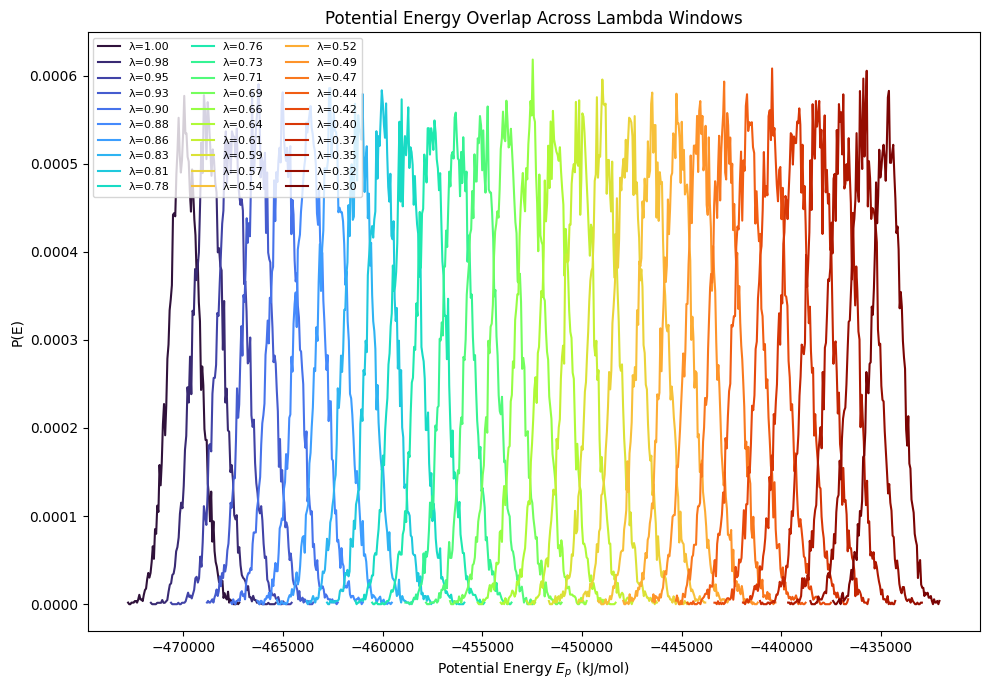

In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Plot Potential Energy Overlap
#   Input:  2d/lambda_XXX/potential.xvg
# ============================================================

main_dir = "2d"

lambdas = np.linspace(1.00, 0.30, 30)
labels = [int(round(lam * 100)) for lam in lambdas]

cmap = plt.cm.turbo
colors = cmap(np.linspace(0, 1, len(lambdas)))

plt.figure(figsize=(10, 7))

for i, (lam, label) in enumerate(zip(lambdas, labels)):

    pot_file = os.path.join(main_dir, f"lambda_{label}", "potential.xvg")

    if not os.path.exists(pot_file):
        print(f"❌ Missing: {pot_file}")
        continue

    data = np.loadtxt(pot_file)

    if data.ndim == 1:
        continue

    time = data[:, 0]
    pot = data[:, 1]

    pdf, edges = np.histogram(
        pot,
        bins=100,
        density=True
    )

    bin_centers = 0.5 * (edges[:-1] + edges[1:])

    plt.plot(
        bin_centers,
        pdf,
        color=colors[i],
        lw=1.5,
        label=f"λ={lam:.2f}"
    )

plt.xlabel(r"Potential Energy $E_p$ (kJ/mol)")
plt.ylabel("P(E)")
plt.title("Potential Energy Overlap Across Lambda Windows")
plt.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

## ⚡ Inspect Potential-Energy Overlap Using Alternate λ Windows

Plots **every second λ window** to reduce visual crowding and make the **potential-energy overlap between λ replicas easier to assess** after 100 ns of sampling.

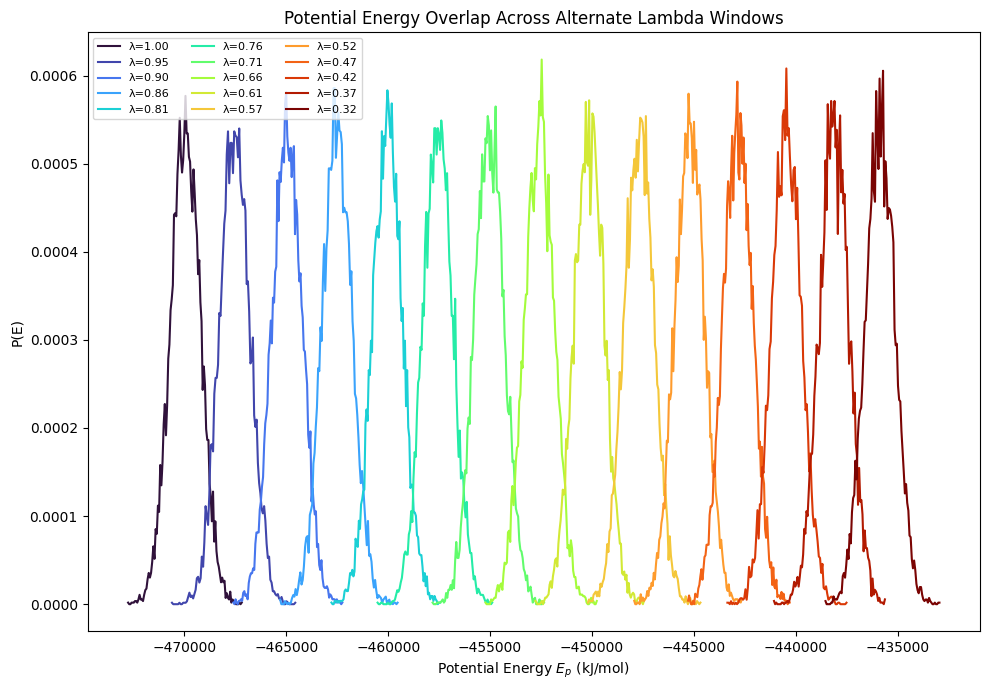

In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Plot Potential Energy Overlap
#   Alternate lambda windows only
# ============================================================

main_dir = "2d"

lambdas = np.linspace(1.00, 0.30, 30)[::2]
labels = [int(round(lam * 100)) for lam in lambdas]

cmap = plt.cm.turbo
colors = cmap(np.linspace(0, 1, len(lambdas)))

plt.figure(figsize=(10, 7))

for i, (lam, label) in enumerate(zip(lambdas, labels)):

    pot_file = os.path.join(
        main_dir,
        f"lambda_{label}",
        "potential.xvg"
    )

    if not os.path.exists(pot_file):
        print(f"❌ Missing: {pot_file}")
        continue

    data = np.loadtxt(pot_file)

    if data.ndim == 1:
        continue

    pot = data[:, 1]

    pdf, edges = np.histogram(
        pot,
        bins=100,
        density=True
    )

    centers = 0.5 * (
        edges[:-1] +
        edges[1:]
    )

    plt.plot(
        centers,
        pdf,
        lw=1.5,
        color=colors[i],
        label=f"λ={lam:.2f}"
    )

plt.xlabel(r"Potential Energy $E_p$ (kJ/mol)")
plt.ylabel("P(E)")
plt.title(
    "Potential Energy Overlap Across Alternate Lambda Windows"
)

plt.legend(
    fontsize=8,
    ncol=3
)

plt.tight_layout()
plt.show()

### 🔎 Inference After 100 ns

After 100 ns, the neighboring λ windows show **substantial potential-energy overlap**, supporting the selected λ range and spacing for replica exchange. Increasing tempering progressively broadens the conformational sampling, with the lower λ replicas reaching **RMSD values >1 nm and up to ~2 nm**, while the radius of gyration remains relatively constrained. This is encouraging because the replicas are exploring conformations far from the starting structure without obvious global expansion of the protein. The highly displaced states may therefore represent **intermediate or partially unfolded conformations**, similar to those sampled in the urea and SMOG simulations, although this will require structural analysis to confirm. 

Overall, this test provides a **blueprint for selecting the λ range** for the expanded 64-replica setup with replica exchange. In particular, the RMSD profiles identify the λ regime where sampling begins to cross **~1.5 nm RMSD**, a range associated with the intermediate/partially unfolded conformations observed in the urea and SMOG simulations. This λ range will therefore guide the design of the denser 64-replica ladder to better sample these states.
*******

### 🎬 Bonus: Visual Inspection of Low-λ Trajectories

Because the low-λ replicas reach RMSD values of approximately **1.5 nm**, similar to the intermediate conformations observed in the **urea and SMOG simulations**, trajectories at **λ = 0.52 and 0.40** were visualized to assess whether they show comparable structural features.

In [11]:
!echo 1 1 | gmx_mpi trjconv -f 2d/lambda_52/topol.xtc -s 2d/lambda_52/topol.tpr -center -pbc mol -skip 50 -o 2d/lambda_52/lambda_52_movie.pdb

!echo 1 1 | gmx_mpi trjconv -f 2d/lambda_40/topol.xtc -s 2d/lambda_40/topol.tpr -center -pbc mol -skip 50 -o 2d/lambda_40/lambda_40_movie.pdb

               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONJ
Command line:
  gmx_mpi trjconv -f 2d/lambda_52/topol.xtc -s 2d/lambda_52/topol.tpr -center -pbc mol -skip 50 -o 2d/lambda_52/lambda_52_movie.pdb

Note that major changes are planned in future for trjconv, to improve usability and utility.
Will write pdb: Protein data bank file
Reading file 2d/lambda_52/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file 2d/lambda_52/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Select group for centering
Group     0 (         System) has 36986 elements
Group     1 (        Protein) has  4422 elements
Group     2 (      Protein-H) has  2178 elements
Group     3 (        C-alpha) has   271 elements
Group     4 (       Backbone) has   813 elements
Group     5